In [1]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().resolve().parent   # notebook berada di notebooks/
sys.path.insert(0, str(PROJECT_ROOT))

import numpy as np
import pandas as pd
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
pd.set_option("display.max_columns", 50)

from src.config import CONFIG
from src.preprocessing import (
    load_data, validate_columns, clean_data, print_cleaning_summary,
)
from src.rfm import calculate_customer_rfm

CONFIG.output_dir.mkdir(parents=True, exist_ok=True)
print("Data path         :", CONFIG.data_path)
print("Sheet             :", CONFIG.sheet_name)
print("Output dir        :", CONFIG.output_dir)
print("Remove non-product:", CONFIG.remove_non_product)

Data path         : D:\UNUD\Semester 5\Machine Learning\project clustering\customer-segmentation\data\online_retail_II.xlsx
Sheet             : Year 2010-2011
Output dir        : D:\UNUD\Semester 5\Machine Learning\project clustering\customer-segmentation\outputs
Remove non-product: False


In [2]:
raw = load_data(CONFIG.data_path, CONFIG.sheet_name)
print(f"Raw shape: {raw.shape}")   # ekspektasi: (541910, 8)
raw.head()

Raw shape: (541910, 8)


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,"17,850.00",United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,"17,850.00",United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,"17,850.00",United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,"17,850.00",United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,"17,850.00",United Kingdom


In [3]:
df = validate_columns(raw)

print("Dtypes:")
print(df.dtypes, "\n")

print("Missing values per kolom:")
print(df.isna().sum(), "\n")

print("Rentang tanggal:", df["InvoiceDate"].min(), "->", df["InvoiceDate"].max())
print("Jumlah baris duplikat identik  :", df.duplicated().sum())
print("Invoice cancellation ('C')     :", df["InvoiceNo"].astype(str).str.upper().str.startswith("C").sum())
print("Quantity <= 0                  :", (df["Quantity"] <= 0).sum())
print("UnitPrice <= 0                 :", (df["UnitPrice"] <= 0).sum())
print("Tipe InvoiceNo (campuran)      :", df["InvoiceNo"].map(type).value_counts().to_dict())
df[["Quantity", "UnitPrice"]].describe()

Dtypes:
InvoiceNo              object
StockCode              object
Description            object
Quantity                int64
InvoiceDate    datetime64[ns]
UnitPrice             float64
CustomerID            float64
Country                object
dtype: object 

Missing values per kolom:
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64 

Rentang tanggal: 2010-12-01 08:26:00 -> 2011-12-09 12:50:00
Jumlah baris duplikat identik  : 5268
Invoice cancellation ('C')     : 9288
Quantity <= 0                  : 10624
UnitPrice <= 0                 : 2517
Tipe InvoiceNo (campuran)      : {<class 'int'>: 532619, <class 'str'>: 9291}


,Quantity,UnitPrice
count,"541,910.00","541,910.00"
mean,9.55,4.61
std,218.08,96.76
min,"-80,995.00","-11,062.06"
25%,1.00,1.25
50%,3.00,2.08
75%,10.00,4.13
max,"80,995.00","38,970.00"


In [4]:
df_clean, cleaning_log = clean_data(df, remove_non_product=CONFIG.remove_non_product)
print_cleaning_summary(cleaning_log)
cleaning_log

PREPROCESSING SUMMARY
Rows before      : 541,910
Rows after       : 392,693
Customers before : 4,372
Customers after  : 4,338
------------------------------------------------------------
remove_invalid_invoice_date         removed:          0
remove_missing_customer_id          removed:    135,080
remove_duplicate_rows               removed:      5,225
remove_cancellation                 removed:      8,872
remove_non_positive_quantity        removed:          0
remove_non_positive_unit_price      removed:         40


,step,rows_before,rows_after,rows_removed,customers_after
0,initial,541910,541910,0,4372
1,remove_invalid_invoice_date,541910,541910,0,4372
2,remove_missing_customer_id,541910,406830,135080,4372
3,remove_duplicate_rows,406830,401605,5225,4372
4,remove_cancellation,401605,392733,8872,4339
5,remove_non_positive_quantity,392733,392733,0,4339
6,remove_non_positive_unit_price,392733,392693,40,4338


In [5]:
# Validasi log: baris awal - total dihapus = baris akhir
initial_rows = int(cleaning_log.iloc[0]["rows_before"])
total_removed = int(cleaning_log["rows_removed"].sum())
assert initial_rows - total_removed == len(df_clean), "Log preprocessing tidak konsisten"
print(f"OK: {initial_rows:,} - {total_removed:,} = {len(df_clean):,}")

OK: 541,910 - 149,217 = 392,693


In [6]:
non_product = df_clean[~df_clean["StockCode"].str.match(r"^\d{5}")]
print(f"Baris StockCode non-produk pada data bersih: {len(non_product):,}")
print(f"Revenue dari baris tersebut               : {non_product['Revenue'].sum():,.2f}")
non_product["StockCode"].value_counts()

Baris StockCode non-produk pada data bersih: 1,543
Revenue dari baris tersebut               : 149,999.25


StockCode
POST            1100
M                279
C2               133
DOT               16
BANK CHARGES      12
PADS               3
Name: count, dtype: int64

In [7]:
df_clean.to_csv(CONFIG.output_dir / "cleaned_data.csv", index=False)
cleaning_log.to_csv(CONFIG.output_dir / "cleaning_log.csv", index=False)
print("Tersimpan: cleaned_data.csv, cleaning_log.csv")
df_clean.head()

Tersimpan: cleaned_data.csv, cleaning_log.csv


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Revenue
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34


In [8]:
reference_date = df_clean["InvoiceDate"].max() + pd.Timedelta(days=1)
print("Reference date:", reference_date)

rfm = calculate_customer_rfm(df_clean, reference_date=reference_date)
print(f"Jumlah customer: {len(rfm):,}")
rfm.head(10)

Reference date: 2011-12-10 12:50:00
Jumlah customer: 4,338


,CustomerID,LastPurchaseDate,Recency,Frequency,Monetary
0,12346,2011-01-18 10:01:00,326,1,"77,183.60"
1,12347,2011-12-07 15:52:00,2,7,"4,310.00"
2,12348,2011-09-25 13:13:00,75,4,"1,797.24"
3,12349,2011-11-21 09:51:00,19,1,"1,757.55"
4,12350,2011-02-02 16:01:00,310,1,334.40
5,12352,2011-11-03 14:37:00,36,8,"2,506.04"
6,12353,2011-05-19 17:47:00,204,1,89.00
7,12354,2011-04-21 13:11:00,232,1,"1,079.40"
8,12355,2011-05-09 13:49:00,214,1,459.40
9,12356,2011-11-17 08:40:00,23,3,"2,811.43"


In [9]:
assert rfm["CustomerID"].is_unique, "CustomerID tidak unik"
assert len(rfm) == df_clean["CustomerID"].nunique(), "Jumlah customer tidak konsisten"
assert (rfm["Recency"] >= 1).all(), "Recency < 1 ditemukan"
assert (rfm["Frequency"] >= 1).all(), "Frequency < 1 ditemukan"
assert (rfm["Monetary"] > 0).all(), "Monetary <= 0 ditemukan"
assert np.isclose(rfm["Monetary"].sum(), df_clean["Revenue"].sum()), "Total Monetary != total Revenue"
print("Semua sanity check lolos.\n")

# Verifikasi manual satu customer
cid = rfm["CustomerID"].iloc[0]
sub = df_clean[df_clean["CustomerID"] == cid]
print(f"Customer {cid}:")
print("  Last purchase manual :", sub["InvoiceDate"].max())
print("  Recency manual       :", (reference_date - sub["InvoiceDate"].max()).days)
print("  Frequency manual     :", sub["InvoiceNo"].nunique())
print("  Monetary manual      :", round(sub["Revenue"].sum(), 2))
print("Bandingkan dengan baris pertama tabel RFM di atas.")

Semua sanity check lolos.

Customer 12346:
  Last purchase manual : 2011-01-18 10:01:00
  Recency manual       : 326
  Frequency manual     : 1
  Monetary manual      : 77183.6
Bandingkan dengan baris pertama tabel RFM di atas.


In [10]:
print(rfm[["Recency", "Frequency", "Monetary"]].describe())
print(f"\nCustomer dengan Frequency = 1 : {(rfm['Frequency'] == 1).mean():.1%}")
print("Monetary tertinggi:")
print(rfm.nlargest(5, "Monetary")[["CustomerID", "Frequency", "Monetary"]])
print("\nSkewness (nilai besar = sangat miring ke kanan):")
print(rfm[["Recency", "Frequency", "Monetary"]].skew())

       Recency  Frequency   Monetary
count 4,338.00   4,338.00   4,338.00
mean     92.54       4.27   2,048.69
std     100.01       7.70   8,985.23
min       1.00       1.00       3.75
25%      18.00       1.00     306.48
50%      51.00       2.00     668.57
75%     142.00       5.00   1,660.60
max     374.00     209.00 280,206.02

Customer dengan Frequency = 1 : 34.4%
Monetary tertinggi:
      CustomerID  Frequency   Monetary
1689       14646         73 280,206.02
4201       18102         60 259,657.30
3728       17450         46 194,390.79
3008       16446          2 168,472.50
1879       14911        201 143,711.17

Skewness (nilai besar = sangat miring ke kanan):
Recency      1.25
Frequency   12.07
Monetary    19.34
dtype: float64


In [11]:
rfm.to_csv(CONFIG.output_dir / "customer_features.csv", index=False)
print("Tersimpan:", CONFIG.output_dir / "customer_features.csv")

Tersimpan: D:\UNUD\Semester 5\Machine Learning\project clustering\customer-segmentation\outputs\customer_features.csv


In [15]:
p = PROJECT_ROOT / "src" / "clv.py"
print(p)
print(p.stat().st_size, "bytes")
print("def create_calibration_holdout" in p.read_text(encoding="utf-8"))

D:\UNUD\Semester 5\Machine Learning\project clustering\customer-segmentation\src\clv.py
12759 bytes
True


In [17]:
import sys
for name in [k for k in sys.modules if k == "src" or k.startswith("src.")]:
    del sys.modules[name]

from src.clv import (
    create_calibration_holdout, build_clv_summary, fit_bgnbd, diagnose_bgnbd,
    fit_gamma_gamma, calculate_predictive_clv, evaluate_clv_prediction,
)
import matplotlib.pyplot as plt
print("Import berhasil")

Import berhasil


In [18]:
from src.clv import (
    create_calibration_holdout, build_clv_summary, fit_bgnbd, diagnose_bgnbd,
    fit_gamma_gamma, calculate_predictive_clv, evaluate_clv_prediction,
)
import matplotlib.pyplot as plt

In [19]:
calibration, holdout, cutoff = create_calibration_holdout(df_clean, CONFIG.holdout_days)

print("Cutoff calibration :", cutoff.date())
print(f"Calibration : {calibration['InvoiceDate'].min()} -> {calibration['InvoiceDate'].max()}  ({len(calibration):,} baris, {calibration['CustomerID'].nunique():,} customer)")
print(f"Holdout     : {holdout['InvoiceDate'].min()} -> {holdout['InvoiceDate'].max()}  ({len(holdout):,} baris, {holdout['CustomerID'].nunique():,} customer)")

new_in_holdout = set(holdout["CustomerID"]) - set(calibration["CustomerID"])
print(f"Customer yang baru muncul di holdout (tidak bisa diprediksi): {len(new_in_holdout):,}")

# Cek anti-leakage
assert calibration["InvoiceDate"].max() < holdout["InvoiceDate"].min(), "Calibration dan holdout tumpang tindih"
assert len(calibration) + len(holdout) == len(df_clean), "Ada baris hilang saat split"
print("Cek split: OK")

Cutoff calibration : 2011-09-10
Calibration : 2010-12-01 08:26:00 -> 2011-09-09 15:53:00  (233,840 baris, 3,370 customer)
Holdout     : 2011-09-11 10:35:00 -> 2011-12-09 12:50:00  (158,853 baris, 2,889 customer)
Customer yang baru muncul di holdout (tidak bisa diprediksi): 968
Cek split: OK


In [21]:
import sys
for name in [k for k in sys.modules if k == "src" or k.startswith("src.")]:
    del sys.modules[name]

from src.config import CONFIG
print("bgnbd_penalizer:", CONFIG.bgnbd_penalizer)
print("gg_penalizer   :", CONFIG.gg_penalizer)
print("log_transform  :", CONFIG.log_transform)

bgnbd_penalizer: 0.05
gg_penalizer   : 0.0
log_transform  : True


In [22]:
summary_cal = build_clv_summary(calibration, cutoff)
print(f"Customer di calibration: {len(summary_cal):,}")
print(f"Tanpa pembelian ulangan (lt_frequency = 0): {(summary_cal['lt_frequency'] == 0).mean():.1%}")
display(summary_cal.describe())

bgf, used_pen = fit_bgnbd(summary_cal, CONFIG.bgnbd_penalizer)
diag = diagnose_bgnbd(bgf)
print("\nBG/NBD  penalizer dipakai:", used_pen)
print("BG/NBD  parameter        :", diag["params"])
print("BG/NBD  dropout degenerate:", diag["dropout_degenerate"])

ggf, corr_fm = fit_gamma_gamma(summary_cal, CONFIG.gg_penalizer)
print("\nGamma-Gamma parameter    :", {k: round(float(v), 3) for k, v in ggf.params_.items()})
print(f"Korelasi frequency-monetary (asumsi independen; idealnya kecil): {corr_fm:.3f}")

Customer di calibration: 3,370
Tanpa pembelian ulangan (lt_frequency = 0): 42.0%


,lt_frequency,lt_recency,lt_T,lt_monetary
count,"3,370.00","3,370.00","3,370.00","3,370.00"
mean,2.21,87.91,182.90,242.22
std,4.63,95.48,80.46,566.47
min,0.00,0.00,1.00,0.00
25%,0.00,0.00,123.00,0.00
50%,1.00,55.00,193.00,135.01
75%,3.00,170.00,265.00,328.47
max,82.00,282.00,283.00,"21,535.90"



BG/NBD  penalizer dipakai: 0.05
BG/NBD  parameter        : {'r': 0.5938, 'alpha': 54.008, 'a': 0.0, 'b': 0.0}
BG/NBD  dropout degenerate: True

Gamma-Gamma parameter    : {'p': 2.332, 'q': 3.334, 'v': 410.207}
Korelasi frequency-monetary (asumsi independen; idealnya kecil): 0.105


In [23]:
eval_months = int(round(CONFIG.holdout_days / 30))   # horizon prediksi = panjang holdout
pred_cal = calculate_predictive_clv(bgf, ggf, summary_cal, eval_months, CONFIG.discount_rate)

metrics, decile = evaluate_clv_prediction(summary_cal, pred_cal, holdout)
print(f"Horizon evaluasi: {eval_months} bulan (= {CONFIG.holdout_days} hari holdout)\n")
pd.Series(metrics).to_frame("value")

Horizon evaluasi: 3 bulan (= 90 hari holdout)



,value
n_customers_evaluated,"3,370.00"
n_active_in_holdout,"1,921.00"
purchases_spearman,0.50
purchases_pearson,0.79
purchases_MAE,0.93
purchases_RMSE,1.51
purchases_total_predicted,"3,314.24"
purchases_total_actual,"4,482.00"
clv_spearman_vs_revenue,0.51
clv_pearson_vs_revenue,0.66


In [24]:
decile

,CLV_Decile,n,mean_predicted_clv,mean_actual_revenue,mean_expected_purchases,mean_actual_purchases
0,1,337,70.08,164.16,0.17,0.49
1,2,337,91.80,209.40,0.23,0.46
2,3,337,119.30,708.31,0.34,0.54
3,4,337,153.36,286.37,0.48,0.80
4,5,337,197.06,244.20,0.65,0.86
5,6,337,244.35,305.46,0.79,0.99
6,7,337,309.03,410.28,0.95,1.12
7,8,337,406.30,602.88,1.27,1.48
8,9,337,610.52,"1,074.72",1.67,2.19
9,10,337,"2,372.01","4,432.96",3.27,4.37


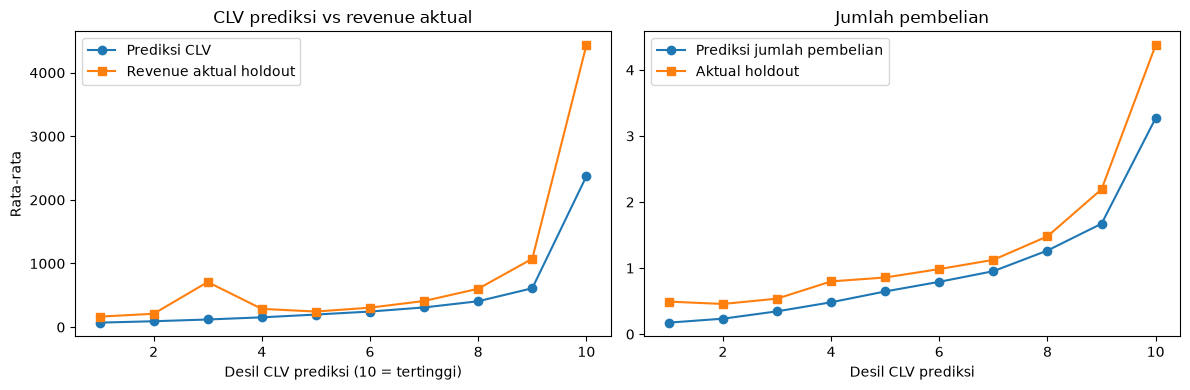

In [25]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(decile["CLV_Decile"], decile["mean_predicted_clv"], marker="o", label="Prediksi CLV")
ax[0].plot(decile["CLV_Decile"], decile["mean_actual_revenue"], marker="s", label="Revenue aktual holdout")
ax[0].set_xlabel("Desil CLV prediksi (10 = tertinggi)"); ax[0].set_ylabel("Rata-rata"); ax[0].set_title("CLV prediksi vs revenue aktual"); ax[0].legend()
ax[1].plot(decile["CLV_Decile"], decile["mean_expected_purchases"], marker="o", label="Prediksi jumlah pembelian")
ax[1].plot(decile["CLV_Decile"], decile["mean_actual_purchases"], marker="s", label="Aktual holdout")
ax[1].set_xlabel("Desil CLV prediksi"); ax[1].set_title("Jumlah pembelian"); ax[1].legend()
plt.tight_layout(); plt.show()

In [26]:
print("Ringkasan evaluasi CLV")
print(f"  Spearman CLV vs revenue aktual      : {metrics['clv_spearman_vs_revenue']:.3f}")
print(f"  Pembanding naif (Frequency)         : {metrics['baseline_spearman_frequency']:.3f}")
print(f"  Pembanding naif (Monetary historis) : {metrics['baseline_spearman_hist_monetary']:.3f}")
print(f"  Total pembelian prediksi vs aktual  : {metrics['purchases_total_predicted']:,.0f} vs {metrics['purchases_total_actual']:,.0f}")
print(f"  Total CLV prediksi vs revenue aktual: {metrics['clv_total_predicted']:,.0f} vs {metrics['revenue_total_actual']:,.0f}")
pd.Series(metrics).to_frame("value").to_csv(CONFIG.output_dir / "clv_evaluation_metrics.csv")
decile.to_csv(CONFIG.output_dir / "clv_decile_table.csv", index=False)

Ringkasan evaluasi CLV
  Spearman CLV vs revenue aktual      : 0.513
  Pembanding naif (Frequency)         : 0.493
  Pembanding naif (Monetary historis) : 0.525
  Total pembelian prediksi vs aktual  : 3,314 vs 4,482
  Total CLV prediksi vs revenue aktual: 1,541,367 vs 2,843,857


In [27]:
obs_end = df_clean["InvoiceDate"].max().normalize()
summary_full = build_clv_summary(df_clean, obs_end)
assert len(summary_full) == df_clean["CustomerID"].nunique()

bgf_full, pen_full = fit_bgnbd(summary_full, CONFIG.bgnbd_penalizer)
ggf_full, corr_full = fit_gamma_gamma(summary_full, CONFIG.gg_penalizer)
print("BG/NBD :", diagnose_bgnbd(bgf_full), "| penalizer:", pen_full)
print("Gamma-Gamma:", {k: round(float(v), 3) for k, v in ggf_full.params_.items()}, "| corr F-M:", round(corr_full, 3))

clv_full = calculate_predictive_clv(bgf_full, ggf_full, summary_full, CONFIG.clv_horizon_months, CONFIG.discount_rate)

# Cek kewajaran
assert clv_full["PredictiveCLV"].notna().all(), "Ada CLV NaN"
assert (clv_full["PredictiveCLV"] >= 0).all(), "Ada CLV negatif"
print(f"\nCustomer dengan prediksi diimputasi (ekspektasi populasi): {int(clv_full['ImputedPrediction'].sum())}")
clv_full.describe(percentiles=[0.5, 0.9, 0.99])

BG/NBD : {'params': {'r': 0.6696, 'alpha': 55.8394, 'a': 0.0, 'b': 0.0}, 'dropout_degenerate': True} | penalizer: 0.05
Gamma-Gamma: {'p': 2.111, 'q': 3.437, 'v': 479.646} | corr F-M: 0.016

Customer dengan prediksi diimputasi (ekspektasi populasi): 26


,ProbAlive,ExpectedPurchases,ExpectedAOV,PredictiveCLV
count,"4,338.00","4,338.00","4,338.00","4,338.00"
mean,1.00,1.08,439.69,520.86
std,0.00,1.32,"1,235.43","1,904.29"
min,1.00,0.14,46.89,57.23
50%,1.00,0.74,415.37,258.72
90%,1.00,2.22,532.14,865.64
99%,1.00,5.67,"1,466.35","3,853.99"
max,1.00,27.63,"78,408.37","59,761.30"


In [28]:
clv_full.reset_index().to_csv(CONFIG.output_dir / "clv_predictions.csv", index=False)
print("Tersimpan: clv_predictions.csv")

Tersimpan: clv_predictions.csv


In [29]:
features = rfm.merge(
    clv_full[["ExpectedPurchases", "ExpectedAOV", "PredictiveCLV", "ImputedPrediction"]].reset_index(),
    on="CustomerID", how="left", validate="one_to_one",
)
assert features["PredictiveCLV"].notna().all() and len(features) == len(rfm)
assert features["CustomerID"].is_unique

FEATURE_COLS = ["Recency", "Frequency", "Monetary", "PredictiveCLV"]
features.to_csv(CONFIG.output_dir / "customer_features.csv", index=False)
print(f"Customer: {len(features):,} | fitur clustering: {FEATURE_COLS}")
features[["CustomerID"] + FEATURE_COLS].head(10)

Customer: 4,338 | fitur clustering: ['Recency', 'Frequency', 'Monetary', 'PredictiveCLV']


,CustomerID,Recency,Frequency,Monetary,PredictiveCLV
0,12346,326,1,"77,183.60",64.44
1,12347,2,7,"4,310.00",793.19
2,12348,75,4,"1,797.24",260.63
3,12349,19,1,"1,757.55",332.36
4,12350,310,1,334.40,67.08
5,12352,36,8,"2,506.04",628.64
6,12353,204,1,89.00,94.45
7,12354,232,1,"1,079.40",85.26
8,12355,214,1,459.40,90.95
9,12356,23,3,"2,811.43",199.86


In [30]:
print("Korelasi Spearman antar fitur:")
display(features[FEATURE_COLS].corr(method="spearman").round(3))
print("Korelasi Pearson antar fitur:")
display(features[FEATURE_COLS].corr(method="pearson").round(3))
print("Skewness:"); print(features[FEATURE_COLS].skew().round(2))

Korelasi Spearman antar fitur:


,Recency,Frequency,Monetary,PredictiveCLV
Recency,1.00,-0.56,-0.48,-0.77
Frequency,-0.56,1.00,0.81,0.73
Monetary,-0.48,0.81,1.00,0.74
PredictiveCLV,-0.77,0.73,0.74,1.00


Korelasi Pearson antar fitur:


,Recency,Frequency,Monetary,PredictiveCLV
Recency,1.00,-0.26,-0.12,-0.16
Frequency,-0.26,1.00,0.55,0.53
Monetary,-0.12,0.55,1.00,0.96
PredictiveCLV,-0.16,0.53,0.96,1.00


Skewness:
Recency          1.25
Frequency       12.07
Monetary        19.34
PredictiveCLV   19.44
dtype: float64


In [31]:
import joblib
from src.clustering import standardize_features

X_scaled, scaler, X_pre = standardize_features(
    features, FEATURE_COLS,
    log_transform=CONFIG.log_transform, log_features=CONFIG.log_features,
)
print("log_transform:", CONFIG.log_transform, "| log_features:", CONFIG.log_features)
print("\nSkewness sebelum -> sesudah transformasi + scaling:")
print(pd.DataFrame({"before": features[FEATURE_COLS].skew(), "after": X_scaled.skew()}).round(2))

# Cek: mean ~ 0 dan std ~ 1
assert np.allclose(X_scaled.mean(), 0, atol=1e-8), "Mean tidak ~ 0"
assert np.allclose(X_scaled.std(ddof=0), 1, atol=1e-8), "Std tidak ~ 1"
print("\nCek standardisasi: OK (mean ~ 0, std ~ 1)")
X_scaled.describe().round(3)

log_transform: True | log_features: ('Frequency', 'Monetary', 'PredictiveCLV')

Skewness sebelum -> sesudah transformasi + scaling:
               before  after
Recency          1.25   1.25
Frequency       12.07   1.21
Monetary        19.34   0.40
PredictiveCLV   19.44   0.83

Cek standardisasi: OK (mean ~ 0, std ~ 1)


,Recency,Frequency,Monetary,PredictiveCLV
count,"4,338.00","4,338.00","4,338.00","4,338.00"
mean,0.00,-0.00,0.00,-0.00
std,1.00,1.00,1.00,1.00
min,-0.92,-0.95,-4.00,-1.67
25%,-0.74,-0.95,-0.68,-0.68
50%,-0.41,-0.36,-0.07,-0.06
75%,0.49,0.65,0.66,0.56
max,2.81,5.86,4.73,5.82


In [32]:
joblib.dump(scaler, CONFIG.output_dir / "scaler.joblib")
X_out = X_scaled.copy(); X_out.insert(0, "CustomerID", features["CustomerID"].values)
X_out.to_csv(CONFIG.output_dir / "customer_features_scaled.csv", index=False)
print("Tersimpan: scaler.joblib, customer_features_scaled.csv")

Tersimpan: scaler.joblib, customer_features_scaled.csv
